# Student Performance Analysis: Secondary School Exam Grades in Portugal (2008-2024)

**Dataset:** Santos, Vanneschi and Damásio (2026). *Longitudinal microdata - Secondary education exams - Portugal, 2008-2024*. Zenodo. https://doi.org/10.5281/zenodo.20579358 (CC BY 4.0)

**Main question:** What is linked to the exam grades of secondary school students in Portugal?

**Objectives**
1. Describe how exam grades are distributed
2. See how grades changed from 2008 to 2024
3. Compare public vs private schools, regions, subjects and gender
4. Check how the school (internal) grade relates to the exam grade
5. Compare grades before and after COVID

> Each row = one exam taken by one student. Results show **associations, not proof of cause**.

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
PASS = 9.5   # grades below 9.5 round to below 10 (fail)

## 2. Load the data

Keep **one** of these files in the same folder as this notebook:
- the full Parquet file from Zenodo (6.48M rows, 38.5 MB), or
- a CSV sample (e.g. `secondary_ed_exams_sample.csv`).

The code picks whichever it finds. Only the columns needed are loaded, so the full file also fits in memory.

In [2]:
USE_COLS = ["Year", "Covid", "ExamName", "InternalGrade", "ExamGrade", "FinalGrade",
            "Gender", "Age", "PubPriv", "NUT2Name", "DistrictName"]

parquet_files = sorted(Path(".").glob("*.parquet"))
csv_files = sorted(Path(".").glob("*sample*.csv")) or sorted(Path(".").glob("*.csv"))

if parquet_files:
    src = parquet_files[0]
    df = pd.read_parquet(src, columns=USE_COLS)
elif csv_files:
    src = csv_files[0]
    df = pd.read_csv(src, usecols=lambda c: c in USE_COLS)
else:
    raise FileNotFoundError("Put the Parquet or CSV file in this folder first.")

print("Loaded:", src)
print("Shape :", df.shape)
df.head()

Loaded: secondary_ed_exams_sample.csv
Shape : (50000, 11)


,Year,Covid,ExamName,InternalGrade,ExamGrade,FinalGrade,Gender,Age,PubPriv,DistrictName,NUT2Name
0,2019,Before,Biology and Geology,18.0,15.0,17.0,Female,16.0,Public,Aveiro,Centro
1,2010,Before,Biology and Geology,11.0,10.0,11.0,Female,16.0,Public,Porto,Norte
2,2023,After,Physics and Chemistry A,NaN,8.7,9.0,Female,17.0,Public,Lisboa,AM Lisboa
3,2012,Before,Descriptive Geometry A,18.0,20.0,19.0,Male,16.0,Public,Porto,Norte
4,2022,After,Portuguese,16.0,12.7,NaN,Female,17.0,Public,Viana do Castelo,Norte


### 2.1 Display the last five rows

In [3]:
print(df.tail())

       Year   Covid                 ExamName  InternalGrade  ExamGrade  \
49995  2022   After      Biology and Geology           12.0        6.9   
49996  2024   After      Biology and Geology           17.0       12.6   
49997  2012  Before               Portuguese           16.0       10.9   
49998  2015  Before               Portuguese            NaN        9.7   
49999  2015  Before  Physics and Chemistry A           12.0        4.5   

       FinalGrade  Gender   Age  PubPriv DistrictName   NUT2Name  
49995         NaN  Female  16.0   Public        Braga      Norte  
49996        16.0    Male  16.0   Public       Lisboa  AM Lisboa  
49997        15.0  Female  17.0   Public      Setúbal  AM Lisboa  
49998        10.0  Female  16.0   Public        Porto      Norte  
49999        10.0  Female  16.0  Private        Porto      Norte  


### 2.2 Check the number of rows and columns

`shape` returns (rows, columns).

In [4]:
print("Rows and columns:", df.shape)

Rows and columns: (50000, 11)


### 2.3 Column names and data types

In [5]:
print("Column names:")
print(df.columns)
print("\nData types:")
print(df.dtypes)

Column names:
Index(['Year', 'Covid', 'ExamName', 'InternalGrade', 'ExamGrade', 'FinalGrade',
       'Gender', 'Age', 'PubPriv', 'DistrictName', 'NUT2Name'],
      dtype='object')

Data types:
Year               int64
Covid             object
ExamName          object
InternalGrade    float64
ExamGrade        float64
FinalGrade       float64
Gender            object
Age              float64
PubPriv           object
DistrictName      object
NUT2Name          object
dtype: object


### 2.4 General information and statistical summary

In [6]:
df.info()
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Year           50000 non-null  int64  
 1   Covid          50000 non-null  object 
 2   ExamName       50000 non-null  object 
 3   InternalGrade  29451 non-null  float64
 4   ExamGrade      50000 non-null  float64
 5   FinalGrade     44677 non-null  float64
 6   Gender         50000 non-null  object 
 7   Age            50000 non-null  float64
 8   PubPriv        50000 non-null  object 
 9   DistrictName   50000 non-null  object 
 10  NUT2Name       50000 non-null  object 
dtypes: float64(4), int64(1), object(6)
memory usage: 4.2+ MB
               Year  InternalGrade     ExamGrade    FinalGrade          Age
count  50000.000000   29451.000000  50000.000000  44677.000000  50000.00000
mean    2015.447380      13.674646     10.116308     11.317031     17.34130
std        4.628332       2.6

## 3. Data cleaning and checks

In [7]:
miss = df.isna().mean().mul(100).round(2).rename("missing_%").to_frame()
miss[miss["missing_%"] > 0]

,missing_%
InternalGrade,41.10
FinalGrade,10.65


In [8]:
print("Year range      :", df["Year"].min(), "to", df["Year"].max())
print("ExamGrade range :", df["ExamGrade"].min(), "to", df["ExamGrade"].max())
print("Duplicate rows  :", df.duplicated().sum(), "(identical rows can be genuine here, so not dropped)")

# ExamGrade is the main outcome: keep only rows that have it
before = len(df)
df = df.dropna(subset=["ExamGrade"]).copy()
print(f"Rows with ExamGrade: {len(df):,} of {before:,}")

df["Year"] = df["Year"].astype(int)
if "Covid" not in df.columns or df["Covid"].isna().all():
    df["Covid"] = np.where(df["Year"] <= 2019, "Before", "After")
df["Covid"] = df["Covid"].astype(str).str.split().str[0]   # 'Before (2008-2019)' -> 'Before'

Year range      : 2008 to 2024
ExamGrade range : 0.0 to 20.0
Duplicate rows  : 389 (identical rows can be genuine here, so not dropped)
Rows with ExamGrade: 50,000 of 50,000


### 3.1 Optional: check unusual values with a box plot

A box plot shows unusually low or high values (potential outliers). We do not delete them: a very high exam grade is a genuine result.

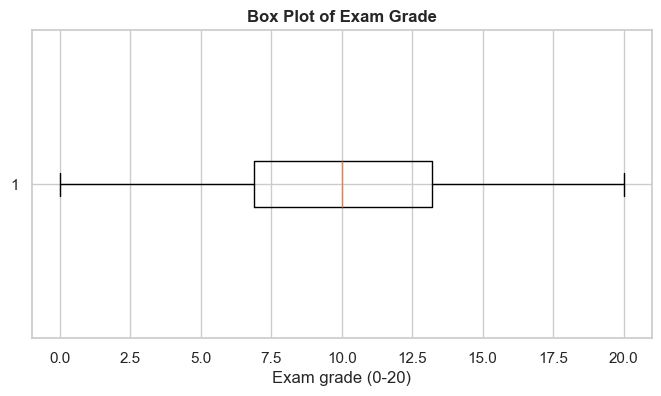

In [9]:
plt.figure(figsize=(8, 4))
plt.boxplot(df["ExamGrade"].dropna(), vert=False)
plt.title("Box Plot of Exam Grade")
plt.xlabel("Exam grade (0-20)")
plt.show()

## 4. Q1. What does a typical exam grade look like?

Average exam grade : 10.12 / 20   (median 10.0)
Share below 9.5    : 43.3%
Share 15 or above  : 14.8%


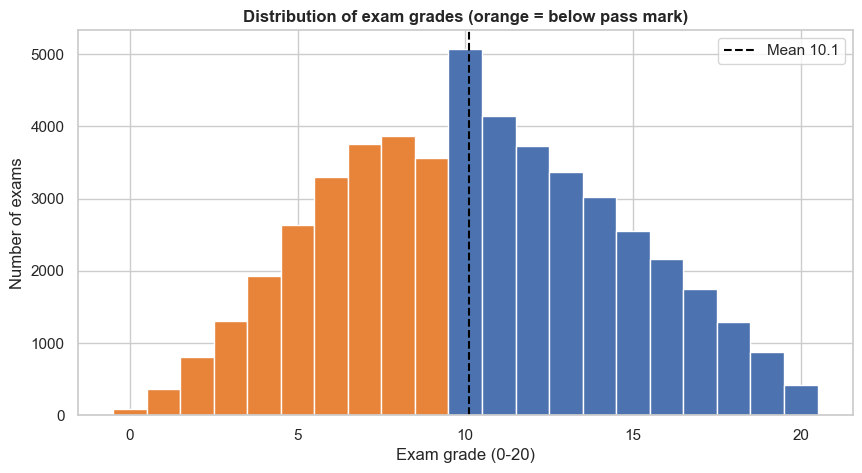

In [10]:
g = df["ExamGrade"]
print(f"Average exam grade : {g.mean():.2f} / 20   (median {g.median():.1f})")
print(f"Share below {PASS}    : {(g < PASS).mean()*100:.1f}%")
print(f"Share 15 or above  : {(g >= 15).mean()*100:.1f}%")

fig, ax = plt.subplots()
bins = np.arange(0, 21.5, 1) - 0.5
n, b, patches = ax.hist(g, bins=bins, edgecolor="white")
for patch, left in zip(patches, b[:-1]):
    patch.set_facecolor("#E8833A" if left + 0.5 < 10 else "#4C72B0")
ax.axvline(g.mean(), color="black", ls="--", label=f"Mean {g.mean():.1f}")
ax.set_xlabel("Exam grade (0-20)"); ax.set_ylabel("Number of exams")
ax.set_title("Distribution of exam grades (orange = below pass mark)")
ax.legend(); plt.show()

**Interpretation prompt:** What is the average grade? Are most exams above or below the pass mark? How many reach 15 or above?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

The average exam grade is about 10.1 out of 20 (median 10). About 43% of exams score below 9.5, which is just under the pass mark, and only about 15% reach 15 or above. So most students score in the middle range and very high grades are uncommon.

## 5. Q2. How did exam grades change over time?

Year,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
mean,10.31,9.93,9.97,9.59,8.89,8.8,9.42,9.87,9.87,9.92,10.15,10.27,12.61,11.11,11.32,11.39,11.22
count,2902.00,3005.00,2989.00,3089.00,3489.00,3583.0,3402.00,3349.00,3435.00,3525.00,3288.00,3253.00,2153.00,1878.00,2087.00,2111.00,2462.00


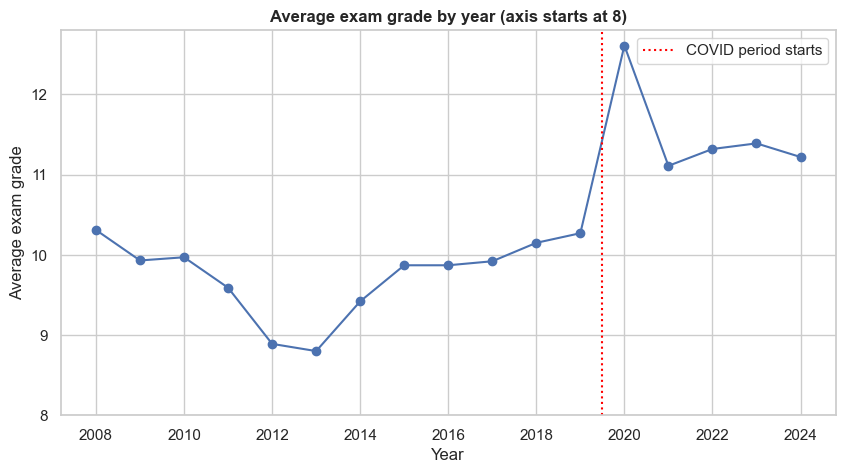

Lowest year : 2013 8.8
Highest year: 2020 12.61


In [11]:
yearly = df.groupby("Year")["ExamGrade"].agg(["mean", "count"]).round(2)
display(yearly.T)

fig, ax = plt.subplots()
ax.plot(yearly.index, yearly["mean"], marker="o", color="#4C72B0")
ax.axvline(2019.5, color="red", ls=":", label="COVID period starts")
ax.set_ylim(8, None)
ax.set_xlabel("Year"); ax.set_ylabel("Average exam grade")
ax.set_title("Average exam grade by year (axis starts at 8)")
ax.legend(); plt.show()

print("Lowest year :", yearly["mean"].idxmin(), yearly["mean"].min())
print("Highest year:", yearly["mean"].idxmax(), yearly["mean"].max())

**Interpretation prompt:** Which years had the lowest and highest average grade? What happened after 2019?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

Grades fell until 2013 (lowest average about 8.8) and then recovered to about 10 by 2019. In 2020 the average jumped to about 12.6 (highest) and stayed above 11 in later years. The big jump in 2020 needs a careful explanation (see Q8).

## 6. Q3. Do private schools score higher?

,mean,records,below_pass
PubPriv,,,
Private,11.25,6294,33.86
Public,9.95,43706,44.62


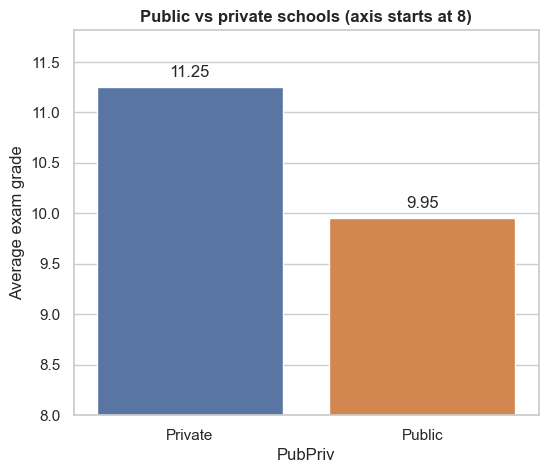

Private share of records: 12.6 %


In [12]:
pp = df.dropna(subset=["PubPriv"]).groupby("PubPriv")["ExamGrade"].agg(
    mean="mean", records="count", below_pass=lambda s: (s < PASS).mean() * 100).round(2)
display(pp)

fig, ax = plt.subplots(figsize=(6, 5))
sns.barplot(x=pp.index, y=pp["mean"], palette=["#4C72B0", "#E8833A"], ax=ax)
for i, v in enumerate(pp["mean"]):
    ax.text(i, v + 0.1, f"{v:.2f}", ha="center")
ax.set_ylim(8, None); ax.set_ylabel("Average exam grade")
ax.set_title("Public vs private schools (axis starts at 8)")
plt.show()
print("Private share of records:", round(pp.loc["Private", "records"] / pp["records"].sum() * 100, 1), "%")

An association, not proof that private schools teach better: private-school students may differ in background and course choice.

**Interpretation prompt:** Which type of school scores higher, and by how much? Why can we not say private schools teach better?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

Private schools have a higher average (about 11.25 vs 9.95 for public), a gap of about 1.3 points. Fewer private-school exams fall below the pass mark (34% vs 45%). This is only an association: private-school students may differ in background and course choice, and private schools are only about 13% of the records.

## 7. Q4. Which regions score highest?

,mean,records
NUT2Name,,
Estrangeiro,9.05,179
RA AÃ§ores,9.52,942
Alentejo,9.67,3030
RA Madeira,9.72,1292
Algarve,9.92,1645
AM Lisboa,10.13,14096
Centro,10.14,10822
Norte,10.25,17994


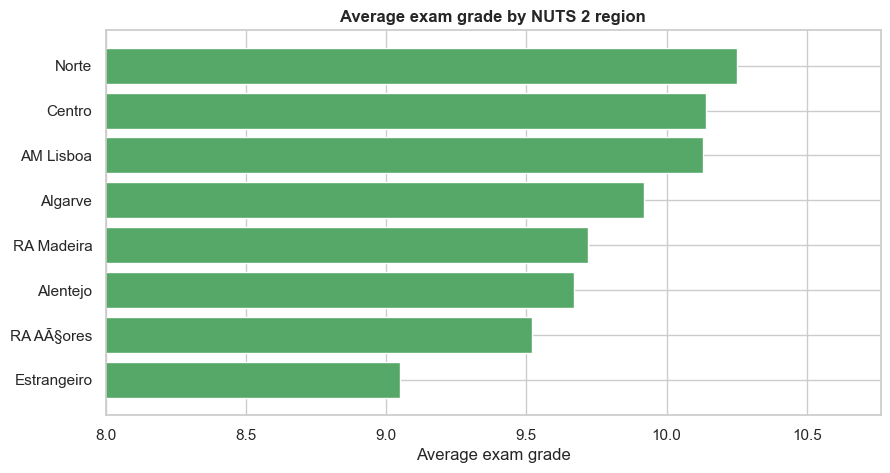

Regions with few records should be read with caution:


,mean,records
NUT2Name,,
Estrangeiro,9.05,179


In [13]:
reg = (df.dropna(subset=["NUT2Name"]).groupby("NUT2Name")["ExamGrade"]
         .agg(mean="mean", records="count").round(2).sort_values("mean"))
display(reg)

fig, ax = plt.subplots()
ax.barh(reg.index, reg["mean"], color="#55A868")
ax.set_xlim(8, None); ax.set_xlabel("Average exam grade")
ax.set_title("Average exam grade by NUTS 2 region")
plt.show()
print("Regions with few records should be read with caution:")
display(reg[reg["records"] < reg["records"].sum() * 0.005])

**Interpretation prompt:** Which region has the highest and lowest average? Do the regions differ a lot? Which regions have very few records?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

Norte has the highest regional average (about 10.3) and Açores the lowest (about 9.5). The mainland regions differ by only about 0.6 points. About 86% of the exams come from Norte, Centro and Lisbon, so regions with few records (such as Abroad) should be read with caution.

## 8. Q5. Which subjects have the lowest grades?

Subjects with at least 800 records: 10


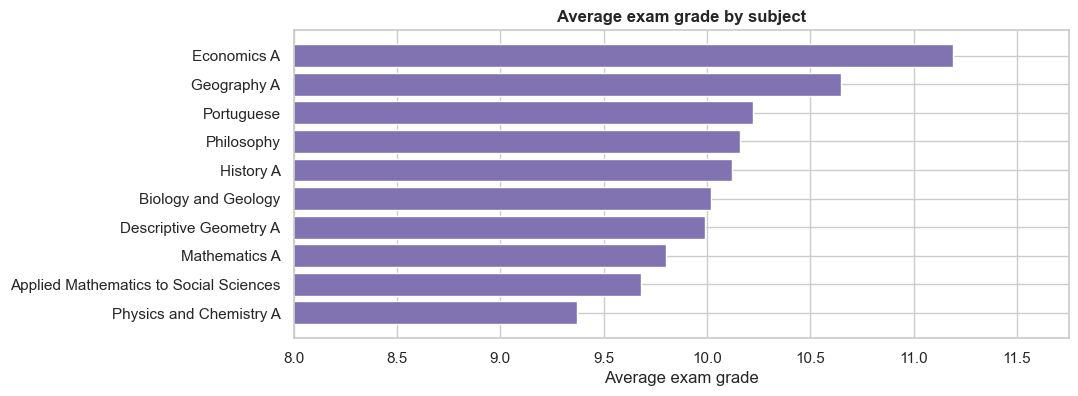

Lowest : Physics and Chemistry A 9.37
Highest: Economics A 11.19


In [14]:
# Only exams with enough records (800 per 50,000 rows, scaled to this file's size)
min_n = max(30, int(len(df) * 800 / 50_000))
subj = (df.groupby("ExamName")["ExamGrade"].agg(mean="mean", records="count")
          .query("records >= @min_n").round(2).sort_values("mean"))
print(f"Subjects with at least {min_n:,} records: {len(subj)}")

fig, ax = plt.subplots(figsize=(10, max(4, len(subj) * 0.35)))
ax.barh(subj.index, subj["mean"], color="#8172B2")
ax.set_xlim(8, None); ax.set_xlabel("Average exam grade")
ax.set_title("Average exam grade by subject")
plt.show()
print("Lowest :", subj["mean"].idxmin(), subj["mean"].min())
print("Highest:", subj["mean"].idxmax(), subj["mean"].max())

**Interpretation prompt:** Which subject has the lowest average and which the highest? Is the gap between subjects large?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

Physics & Chemistry A has the lowest average among large exams (about 9.4) and Economics A the highest (about 11.2). The whole spread is under 2 points, so subject difficulty matters but does not change results dramatically.

## 9. Q6. Do female and male students score differently?

,mean,below_pass
Gender,,
Female,10.35,40.71
Male,9.81,46.63


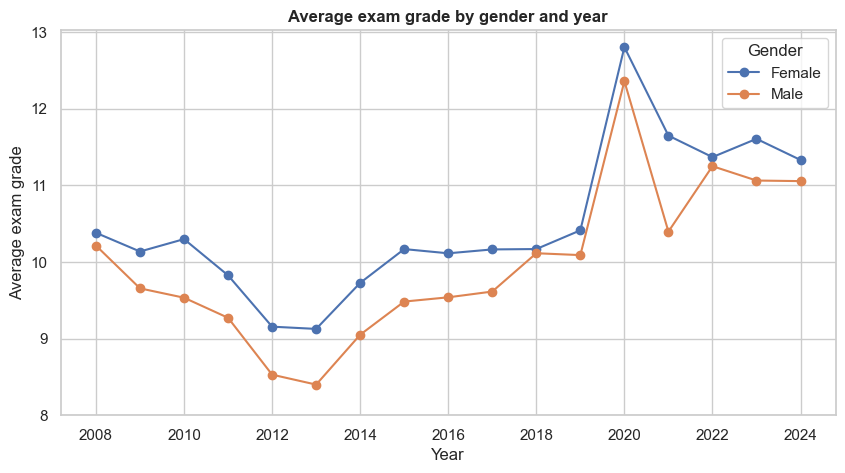

Female average higher in 17 of 17 years


In [15]:
gen = df.dropna(subset=["Gender"]).groupby("Gender")["ExamGrade"].agg(
    mean="mean", below_pass=lambda s: (s < PASS).mean() * 100).round(2)
display(gen)

by_year = df.dropna(subset=["Gender"]).pivot_table(index="Year", columns="Gender",
                                                     values="ExamGrade", aggfunc="mean")
fig, ax = plt.subplots()
by_year.plot(ax=ax, marker="o")
ax.set_ylim(8, None); ax.set_ylabel("Average exam grade")
ax.set_title("Average exam grade by gender and year")
plt.show()

if {"Female", "Male"} <= set(by_year.columns):
    wins = (by_year["Female"] > by_year["Male"]).sum()
    print(f"Female average higher in {wins} of {len(by_year)} years")

**Interpretation prompt:** Do female or male students score higher? Is this true in every year?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

Female students score about 0.5 points higher on average (10.35 vs 9.81), and in this sample they scored higher in every one of the 17 years. The share below the pass mark is 41% for female and 47% for male students. This shows a consistent pattern, not the reason for it.

## 10. Q7. Does the school (internal) grade predict the exam grade?

Exams with an internal grade: 29,451 (59% of rows)
Correlation r = 0.69
Each extra internal point adds about 1.01 points to the exam grade
Internal grades run about 3.0 points above exam grades


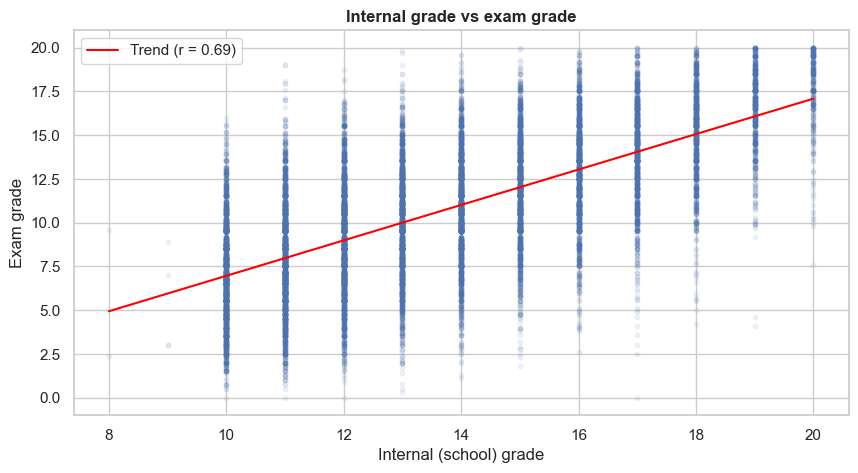

In [16]:
ig = df.dropna(subset=["InternalGrade"])
print(f"Exams with an internal grade: {len(ig):,} ({len(ig)/len(df)*100:.0f}% of rows)")

r = ig["InternalGrade"].corr(ig["ExamGrade"])
slope, intercept = np.polyfit(ig["InternalGrade"], ig["ExamGrade"], 1)
gap = (ig["InternalGrade"] - ig["ExamGrade"]).mean()
print(f"Correlation r = {r:.2f}")
print(f"Each extra internal point adds about {slope:.2f} points to the exam grade")
print(f"Internal grades run about {gap:.1f} points above exam grades")

plot_df = ig.sample(min(20_000, len(ig)), random_state=42)
fig, ax = plt.subplots()
ax.scatter(plot_df["InternalGrade"], plot_df["ExamGrade"], alpha=0.08, s=10)
xs = np.linspace(ig["InternalGrade"].min(), ig["InternalGrade"].max(), 50)
ax.plot(xs, slope * xs + intercept, color="red", label=f"Trend (r = {r:.2f})")
ax.set_xlabel("Internal (school) grade"); ax.set_ylabel("Exam grade")
ax.set_title("Internal grade vs exam grade"); ax.legend(); plt.show()

**Interpretation prompt:** What is the correlation between internal grade and exam grade? What does the trend line say?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

The correlation is about r = 0.69, a strong positive link: students with higher school grades usually score higher in the exam. Each extra internal point adds about 1 point to the average exam grade, and internal grades run about 3 points above exam grades. This is a link, not proof of cause, and only exams with an internal grade (about 59% of rows) are included.

## 11. Q8. Did grades change after COVID?

,mean,records,below_pass
Covid,,,
After,11.53,10691,31.01
Before,9.73,39309,46.59


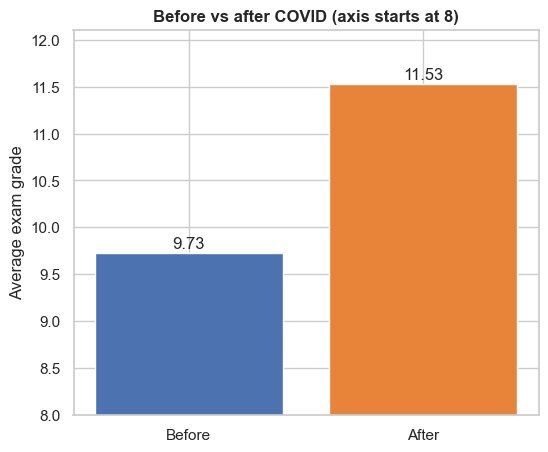

Change: +1.80 points


In [17]:
cv = df.groupby("Covid")["ExamGrade"].agg(
    mean="mean", records="count", below_pass=lambda s: (s < PASS).mean() * 100).round(2)
display(cv)

fig, ax = plt.subplots(figsize=(6, 5))
order = [x for x in ["Before", "After"] if x in cv.index]
ax.bar(order, cv.loc[order, "mean"], color=["#4C72B0", "#E8833A"][:len(order)])
for i, k in enumerate(order):
    ax.text(i, cv.loc[k, "mean"] + 0.05, f"{cv.loc[k, 'mean']:.2f}", ha="center")
ax.set_ylim(8, None); ax.set_ylabel("Average exam grade")
ax.set_title("Before vs after COVID (axis starts at 8)")
plt.show()

if {"Before", "After"} <= set(cv.index):
    print(f"Change: {cv.loc['After','mean'] - cv.loc['Before','mean']:+.2f} points")

Timing alone does not prove COVID was the cause. Changes in exam rules or grading could also play a part.

**Interpretation prompt:** Did the average grade change after COVID? Does this prove COVID caused the change?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

The average grade rose from about 9.73 before 2020 to 11.53 from 2020 onwards (about +1.8 points), and the share below the pass mark fell from 47% to 31%. Timing alone does not prove COVID was the cause: changes in exam rules or grading could also play a part.

## 12. Additional analysis: correlation heatmap

A heatmap uses colours to show how strongly numeric columns are related.

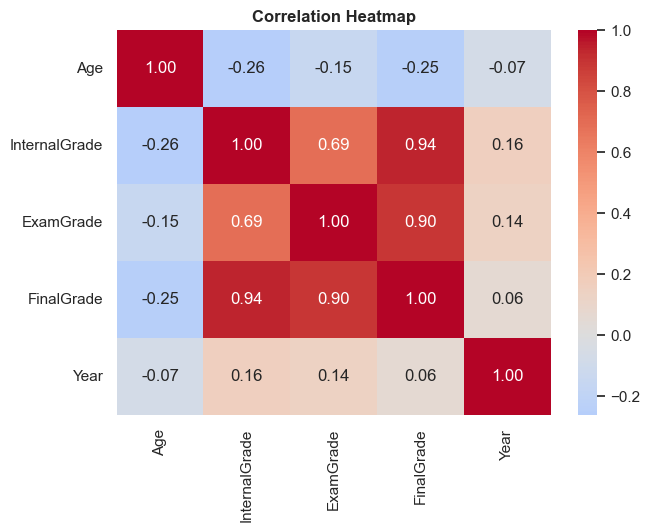

In [18]:
num = df[["Age", "InternalGrade", "ExamGrade", "FinalGrade", "Year"]]
plt.figure(figsize=(7, 5))
sns.heatmap(num.corr(), annot=True, cmap="coolwarm", fmt=".2f", center=0)
plt.title("Correlation Heatmap")
plt.show()

**Interpretation prompt:** Which pairs of columns are strongly related? Which are weakly related?

**My interpretation** (draft from the 50,000-row sample; check against your output and rewrite in your own words):

(Write after running) InternalGrade, ExamGrade and FinalGrade should show strong positive correlations with each other, while Age and Year are likely to be only weakly related to the grades. Correlation does not prove causation.

## 13. Summary table (for the PPT)

In [19]:
summary = pd.Series({
    "Rows used": f"{len(df):,}",
    "Average exam grade": round(df["ExamGrade"].mean(), 2),
    "Share below pass mark (%)": round((df["ExamGrade"] < PASS).mean() * 100, 1),
    "Lowest year": f"{yearly['mean'].idxmin()} ({yearly['mean'].min()})",
    "Highest year": f"{yearly['mean'].idxmax()} ({yearly['mean'].max()})",
    "Private - Public gap": round(pp.loc["Private", "mean"] - pp.loc["Public", "mean"], 2),
    "Best region": reg["mean"].idxmax(),
    "Lowest subject": subj["mean"].idxmin(),
    "Female - Male gap": round(gen.loc["Female", "mean"] - gen.loc["Male", "mean"], 2),
    "Internal vs exam correlation": round(r, 2),
    "After - Before COVID": round(cv.loc["After", "mean"] - cv.loc["Before", "mean"], 2),
}, name="Value")
summary.to_frame()

,Value
Rows used,"50,000"
Average exam grade,10.12
Share below pass mark (%),43.3
Lowest year,2013 (8.8)
Highest year,2020 (12.61)
Private - Public gap,1.3
Best region,Norte
Lowest subject,Physics and Chemistry A
Female - Male gap,0.54
Internal vs exam correlation,0.69


## 14. Conclusion

Write this after running on the **full** data, using the summary table above:

- Overall level of grades and the share below the pass mark
- Trend from 2008 to 2024 and the COVID-period jump
- Private vs public, gender, region and subject differences
- Strength of the link between internal and exam grades

**Limitations:** results are associations, not proof of cause; `ID` repeats across years so one student's exams cannot be linked; `InternalGrade` is missing for many rows; column meanings should be checked against the dataset readme.

**Future work:** regression or tree models to predict `ExamGrade`, and a Django + Chart.js dashboard of these results.

---
**Citation:** Santos, S., Vanneschi, L. and Damásio, B. (2026). *Longitudinal microdata - Secondary education exams - Portugal, 2008-2024* (v.2024.0.0). Zenodo. https://doi.org/10.5281/zenodo.20579358 (CC BY 4.0)